# 01 - Exploratory Data Analysis: Upwork job postings (Feb-Mar 2024)

**Goal.** Understand what the data can and cannot support *before* modelling the eight tasks in the brief.
Every cleaning rule in `src/common.py` is justified by something found here.

**Questions**
1. What is in the file, and how much is missing?
2. Is the time coverage complete? Are there scrape gaps?
3. How are pay (hourly and fixed) and country distributed, and what needs cleaning?
4. How good is a title-keyword category scheme, given the file has no category column?
5. What differs across categories and countries (a first look at Tasks 1, 2 and 4)?

In [1]:
import sys, warnings; warnings.filterwarnings("ignore")
sys.path.insert(0, "..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.common import load_raw, load_clean

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.2f}".format
raw = load_raw()
raw.head()

,title,link,published_date,is_hourly,hourly_low,hourly_high,budget,country
0,Experienced Media Buyer For Solar Pannel and R...,https://www.upwork.com/jobs/Experienced-Media-...,2024-02-17 09:09:54+00:00,False,NaN,NaN,500.00,NaN
1,Full Stack Developer,https://www.upwork.com/jobs/Full-Stack-Develop...,2024-02-17 09:09:17+00:00,False,NaN,NaN,"1,100.00",United States
2,SMMA Bubble App,https://www.upwork.com/jobs/SMMA-Bubble-App_%7...,2024-02-17 09:08:46+00:00,True,10.00,30.00,NaN,United States
3,Talent Hunter Specialized in Marketing,https://www.upwork.com/jobs/Talent-Hunter-Spec...,2024-02-17 09:08:08+00:00,True,NaN,NaN,NaN,United States
4,Data Engineer,https://www.upwork.com/jobs/Data-Engineer_%7E0...,2024-02-17 09:07:42+00:00,False,NaN,NaN,650.00,India


## 1. Structure and missing values

In [2]:
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")
summary = pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing_%": raw.isna().mean() * 100, "unique": raw.nunique()})
summary

244,828 rows x 8 columns


,dtype,missing_%,unique
title,str,0.00,205470
link,str,0.00,244827
published_date,str,0.00,233640
is_hourly,bool,0.00,2
hourly_low,float64,58.17,114
hourly_high,float64,59.66,227
budget,float64,57.57,768
country,str,2.07,212


**Reading the table.** Only eight columns: a title, a link, a timestamp, a contract-type flag, two hourly-rate fields, a fixed budget and the client country.
There is **no description, skills list, category, experience level or location requirement**, so categories and "remote" signals must be derived from titles.

The missing-value pattern is structural: hourly fields are empty for fixed-price jobs and `budget` is empty for hourly jobs. Let us confirm that.

In [3]:
ct = raw.assign(has_rate=raw.hourly_low.notna() | raw.hourly_high.notna(), has_budget=raw.budget.notna()).groupby("is_hourly")[["has_rate", "has_budget"]].mean() * 100
ct.columns = ["% with hourly rate", "% with budget"]
ct

,% with hourly rate,% with budget
is_hourly,,
False,0.00,100.00
True,72.67,0.00


**Finding.** Fixed-price jobs essentially always have a budget. Hourly jobs, however, **often have no advertised rate** (clients can leave it blank).
That means Task 1 and Task 4 hourly analyses run on only the subset of hourly jobs that state a rate. Rates are therefore *advertised* ranges, and clients who disclose them may differ from those who do not.

## 2. Time coverage and scrape gaps

Days with any postings: 89 | days with >100 postings: 41
Rows on days with <=100 postings: 283


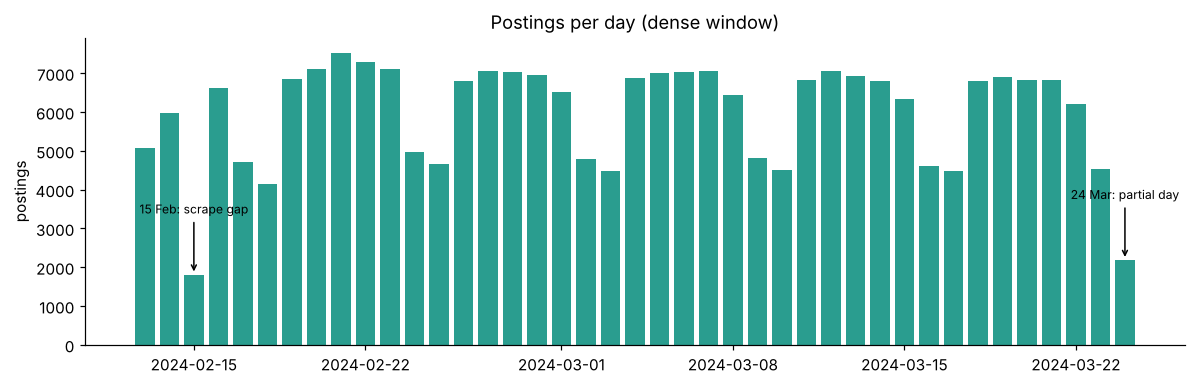

In [4]:
raw["pub"] = pd.to_datetime(raw.published_date, utc=True)
daily = raw.groupby(raw.pub.dt.tz_localize(None).dt.date).size()
daily.index = pd.to_datetime(daily.index)
print("Days with any postings:", len(daily), "| days with >100 postings:", (daily > 100).sum())
print("Rows on days with <=100 postings:", daily[daily <= 100].sum())
dense = daily[daily > 100]
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(dense.index, dense.values, color="#2a9d8f")
ax.set_title("Postings per day (dense window)"); ax.set_ylabel("postings")
for d, t in [("2024-02-15", "15 Feb: scrape gap"), ("2024-03-24", "24 Mar: partial day")]:
    ax.annotate(t, (pd.Timestamp(d), dense[pd.Timestamp(d)]), xytext=(0, 40), textcoords="offset points", ha="center", arrowprops=dict(arrowstyle="->"), fontsize=8)
plt.tight_layout(); plt.show()

**Findings.**
- The file is named 7 Feb - 24 Mar, but the real coverage starts on **13 Feb**. A few hundred stray rows with much earlier timestamps (back to Nov 2023) exist; they are dropped.
- **15 Feb** has only about 1,800 postings versus 5,000-7,500 on normal days: a scrape outage, not a market event. **24 Mar** is a partial day. The forecasting tasks therefore train on 16 Feb - 22 Mar.
- Weekday volume plateaus near **7,000** postings. That flat ceiling suggests the RSS feed was capped, so *absolute* counts understate true volume. **Shares and growth rates are safer than raw counts.**

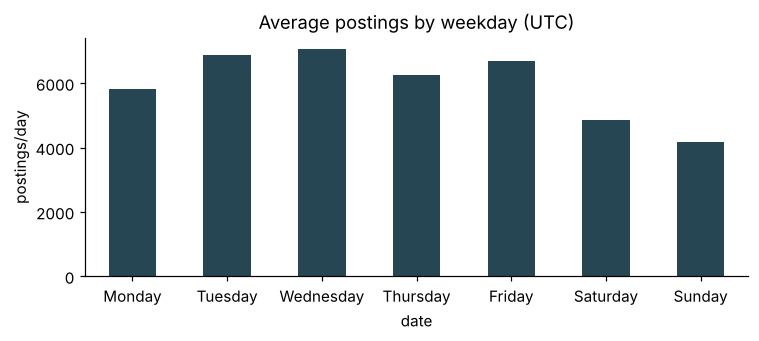

Weekend volume is -31% vs weekdays


In [5]:
df = load_clean()
dow = df.groupby(df.date.dt.day_name()).size().div(df.date.nunique() / 7).reindex(["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"])
fig, ax = plt.subplots(figsize=(7, 3.2))
dow.plot.bar(ax=ax, color="#264653", rot=0); ax.set_title("Average postings by weekday (UTC)"); ax.set_ylabel("postings/day")
plt.tight_layout(); plt.show()
print(f"Weekend volume is {dow[['Saturday','Sunday']].mean() / dow[['Monday','Tuesday','Wednesday','Thursday','Friday']].mean() - 1:+.0%} vs weekdays")

**Finding.** There is a strong weekly cycle with roughly a third fewer postings on weekends. Any model has to include day-of-week effects, otherwise a weekend dip looks like a market decline. This is why Tasks 3, 7 and 8 use weekday terms, and why Task 2 compares two windows that each contain every weekday exactly twice.

## 3. Cleaning: duplicates, text entities and impossible values

In [6]:
print("Duplicate links:", raw.link.duplicated().sum())
print("Raw titles containing HTML entities (&amp; etc.):", raw.title.str.contains(r"&[a-z#0-9]+;").sum())
print(f"After cleaning: {len(df):,} rows ({len(raw) - len(df):,} removed)")
print(f"Postings sharing a title with another posting: {df.title.str.lower().duplicated(keep=False).mean():.1%}")
df.title.value_counts().head(8).to_frame("postings")

Duplicate links: 0
Raw titles containing HTML entities (&amp; etc.): 10130
After cleaning: 244,544 rows (284 removed)
Postings sharing a title with another posting: 23.9%


,postings
title,
Social Media Manager,419
Virtual Assistant,339
Logo Design,311
Video Editor,298
Graphic Designer,292
Logo design,173
Logo Designer,142
Full Stack Developer,136


**Findings.**
- **No duplicate links**, so each row is a unique posting.
- About **10,000 titles contain HTML entities** such as `&amp;`. If left alone, "amp" becomes a frequent keyword and splits "Q&A" or "R&D" in strange ways, so titles are un-escaped on load.
- A noticeable share of postings **reuse an identical title** ("Social Media Manager", "Virtual Assistant", "Logo Design"). These are genuinely different jobs, so they are not de-duplicated for the market analyses, but the **recommender collapses repeated titles** so one generic title cannot fill the whole result list.

In [7]:
r = raw.copy()
issues = pd.Series({
    "hourly_low < $3": (r.hourly_low < 3).sum(),
    "hourly_high > $300": (r.hourly_high > 300).sum(),
    "hourly_low > hourly_high": (r.hourly_low > r.hourly_high).sum(),
    "budget < $5": (r.budget < 5).sum(),
    "budget > $100,000": (r.budget > 100_000).sum(),
}, name="rows")
print(issues.to_string())
print()
print(r.hourly_high.sort_values(ascending=False).value_counts().head(4).to_string())

hourly_low < $3               0
hourly_high > $300          408
hourly_low > hourly_high      0
budget < $5                   0
budget > $100,000            77

hourly_high
30.00    9885
50.00    9329
25.00    7983
35.00    7746


**Findings.** Impossible or placeholder values are rare but would distort means: hourly highs of `$999` (a "no limit" placeholder) and fixed budgets up to `$1,000,000`. The cleaning rule sets hourly values outside **$3-$300** and budgets outside **$5-$100,000** to missing (not dropped, so the title is still usable) and swaps any low/high pair that is reversed.

## 4. Pay distributions

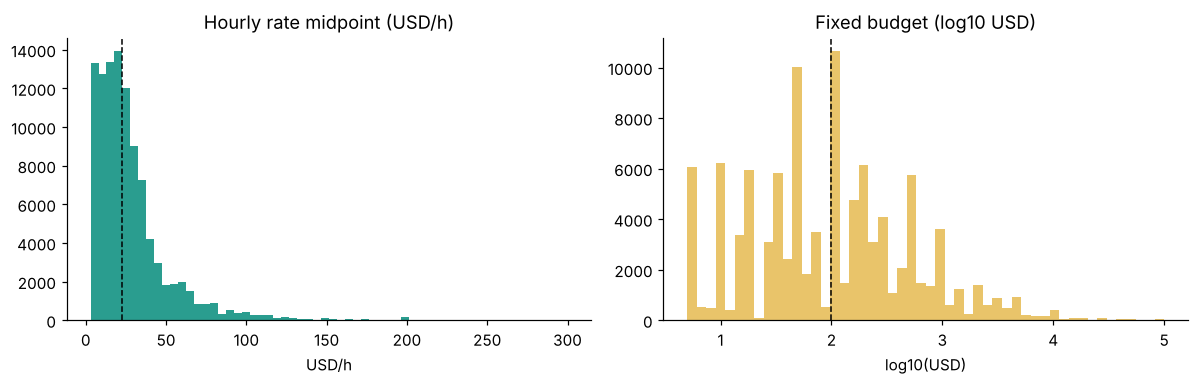

,hourly_mid,budget
quantile,,
0.10,7.50,10.00
0.25,12.50,25.00
0.50,22.50,100.00
0.75,35.00,300.00
0.90,55.00,"1,000.00"
0.99,121.00,"8,000.00"


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(df.hourly_mid.dropna(), bins=60, color="#2a9d8f"); ax[0].set_title("Hourly rate midpoint (USD/h)")
ax[0].axvline(df.hourly_mid.median(), color="k", ls="--", lw=1); ax[0].set_xlabel("USD/h")
ax[1].hist(np.log10(df.budget.dropna()), bins=50, color="#e9c46a"); ax[1].set_title("Fixed budget (log10 USD)")
ax[1].axvline(np.log10(df.budget.median()), color="k", ls="--", lw=1); ax[1].set_xlabel("log10(USD)")
plt.tight_layout(); plt.show()
q = [.1, .25, .5, .75, .9, .99]
pd.DataFrame({"hourly_mid": df.hourly_mid.quantile(q), "budget": df.budget.quantile(q)}).rename_axis("quantile")

**Findings.**
- **Hourly:** median about **$22.50/h**, but a long right tail (the 99th percentile is above $120). The midpoint also clusters on round numbers because clients pick brackets such as $10-$20 or $20-$30.
- **Fixed price:** median **$100**, 90th percentile **$1,000**, 99th percentile **$8,000**. The distribution is close to log-normal, which is why Task 1 models **log pay**, and why medians beat means for every pay comparison.
- Because of the skew, the mean budget (about $590 after cleaning) is nearly six times the median. Reporting means would mislead.

## 5. Contract type and country

Hourly share: 57.5% | Fixed: 42.5%


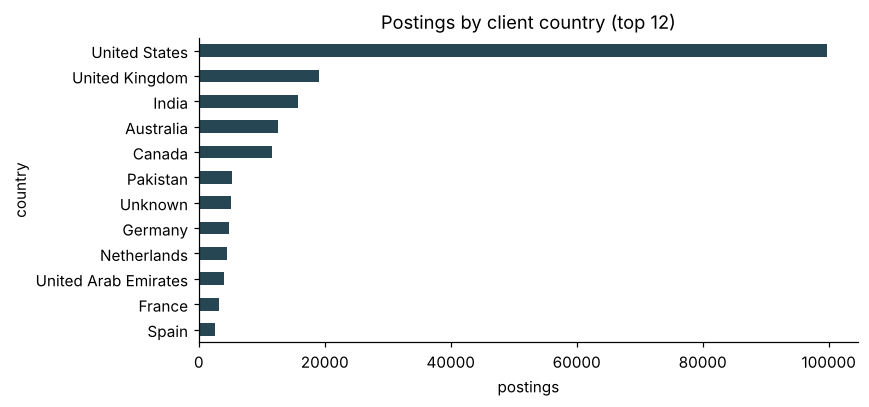

US share: 40.8% | top-5 share: 65.0% | unknown country: 2.1% | distinct countries: 212


In [9]:
print(f"Hourly share: {df.is_hourly.mean():.1%} | Fixed: {1 - df.is_hourly.mean():.1%}")
cs = df.country.value_counts()
top = cs.head(12)
fig, ax = plt.subplots(figsize=(8, 3.8))
top[::-1].plot.barh(ax=ax, color="#264653"); ax.set_title("Postings by client country (top 12)"); ax.set_xlabel("postings")
plt.tight_layout(); plt.show()
print(f"US share: {cs['United States'] / len(df):.1%} | top-5 share: {cs.head(5).sum() / len(df):.1%} | unknown country: {(df.country == 'Unknown').mean():.1%} | distinct countries: {df.country.nunique() - 1}")

**Findings.**
- About **58% of postings are hourly**, 42% fixed-price.
- The US is roughly **41% of postings**, and the top five countries (US, UK, India, Australia, Canada) account for about **65%**. Country-level comparisons (Task 4) are reliable for ~20 countries; the long tail has few postings, so Task 4 requires **at least 30 hourly postings** and reports bootstrap confidence intervals.
- Only ~2% of rows have no country, small enough to label "Unknown" rather than impute.
- Country here is the **client's** country, not the freelancer's.

## 6. Title-derived categories: how good are they?

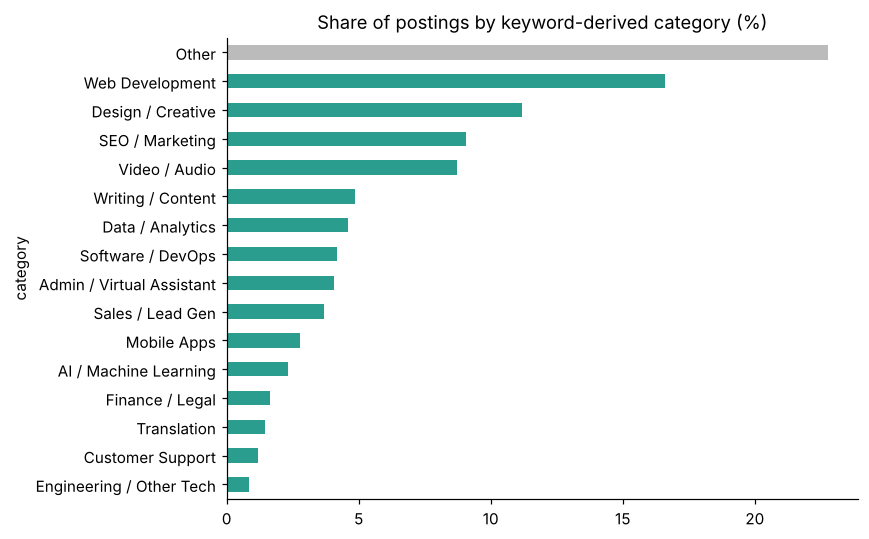

Most common words inside 'Other': expert, needed, need, looking, specialist, create, help, google, business, project, app, product, development, amazon, web, page, english, company, management, online


In [10]:
cat = df.category.value_counts()
fig, ax = plt.subplots(figsize=(8, 5))
(cat[::-1] / len(df) * 100).plot.barh(ax=ax, color=["#bbb" if c == "Other" else "#2a9d8f" for c in cat.index[::-1]])
ax.set_title("Share of postings by keyword-derived category (%)"); plt.tight_layout(); plt.show()
stop = set("for and a to in - the of on with from your my our we i you is are be at as or an it by this that".split())
other_words = df[df.category == "Other"].title.str.lower().str.findall(r"[a-z][a-z+#.]{2,}").explode()
other_words = other_words[~other_words.isin(stop)].value_counts().head(20)
print("Most common words inside 'Other':", ", ".join(other_words.index))

**Findings.**
- Regex rules on titles label about **77%** of postings; **~23% stay "Other"**. Web Development (~17%), Design (~11%), SEO/Marketing (~9%) and Video/Audio (~9%) dominate.
- The words in "Other" are mostly **generic filler** ("expert", "needed", "specialist", "help", "project", "business"), but a few are **missed domain words** ("app", "web", "development", "google", "amazon", "english"). Those are concrete candidates for new or broader rules.
- Rules are applied in priority order, so a title like "Python data scientist" lands in Data or AI depending on rule order. That is a limitation: **one label per posting, no multi-label**. For a sharper taxonomy, embed titles with sentence transformers and cluster, then compare against these rules (listed as a next step in the README).

In [11]:
# Spot-check: random sample of titles per category to eyeball label quality
rng = 7
for c in ["AI / Machine Learning", "Data / Analytics", "Software / DevOps", "Sales / Lead Gen"]:
    print(f"--- {c}")
    for t in df[df.category == c].title.sample(5, random_state=rng):
        print("   ", t[:95])

--- AI / Machine Learning
    Python Developer Needed For AI, Machine Learning, LLM
    Web Developer for AI-Enabled Services Platform - AI Integration
    WhatsApp Automation Custom Chatbot
    Expert Midjourney/Image Generation AI Specialist Prompt Writer
    AI website - Recognize syllables in voice
--- Data / Analytics
    Data scraping
    Google Tag Manager Set Up For Analytics and Ads on Wordpress and Elementor Site
    Financial Analyst & Modeling & Business Valuation
    Serbia data
    Looking for tennis operations support and data entry
--- Software / DevOps
    Console application to index blocks information from the blockchain
    Detection of buy and sells of Solana blockchain programs
    Required a Human Resource expert for product based software company
    GCP Devops Engineer - Docker Deployment
    Creating a Token Contract in Solidity on the Polygon Network for a Metaverse Blockchain Game
--- Sales / Lead Gen
    Press release about a product to drive more leads
   

**Spot-check verdict.** Labels are sensible for most rows. Expect some leakage between neighbouring categories (for example, "lead" appears in both "Sales / Lead Gen" and general titles; "data" pulls in anything with a spreadsheet). Treat category-level conclusions as directional, and prefer conclusions that also hold at the **keyword** level (Tasks 1 and 2 report both).

## 7. First look at pay by category (Task 1 and Task 4 preview)

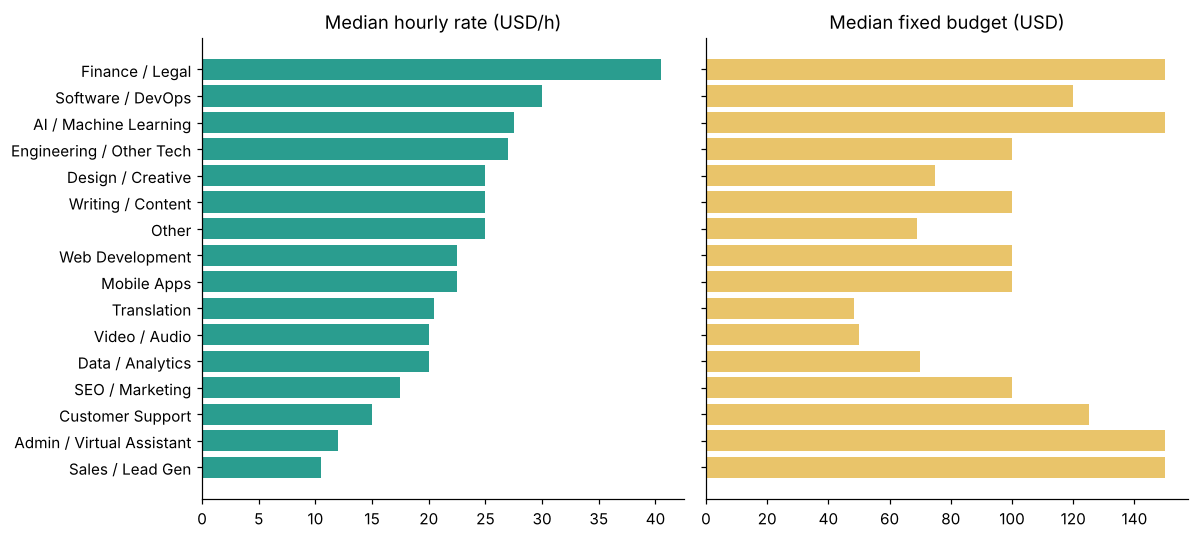

,postings,hourly_share,median_hourly,median_budget
category,,,,
Finance / Legal,3992,69.00,40.50,150.00
Software / DevOps,10238,61.30,30.00,120.00
AI / Machine Learning,5661,58.30,27.50,150.00
Engineering / Other Tech,2094,53.50,27.00,100.00
Design / Creative,27374,50.90,25.00,75.00
Other,55681,53.60,25.00,69.00
Writing / Content,11890,55.50,25.00,100.00
Mobile Apps,6823,45.70,22.50,100.00
Web Development,40575,57.90,22.50,100.00


In [12]:
g = df.groupby("category").agg(postings=("title", "size"), hourly_share=("is_hourly", "mean"), median_hourly=("hourly_mid", "median"), median_budget=("budget", "median"))
g = g.sort_values("median_hourly")
fig, ax = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
ax[0].barh(g.index, g.median_hourly, color="#2a9d8f"); ax[0].set_title("Median hourly rate (USD/h)")
ax[1].barh(g.index, g.median_budget, color="#e9c46a"); ax[1].set_title("Median fixed budget (USD)")
plt.tight_layout(); plt.show()
g.assign(hourly_share=g.hourly_share * 100).round(1).sort_values("median_hourly", ascending=False)

**Findings.**
- Highest hourly medians: **Finance / Legal (~$40)** and **Software / DevOps (~$30)**; lowest: **Sales / Lead Gen (~$10)** and **Admin / Virtual Assistant (~$12)**, which are also the most hourly-heavy categories (70%+ hourly).
- Fixed budgets tell a different story: Admin, Sales and AI sit at **$150 medians**, while Translation (~$50) and Video (~$50) are cheapest. A category can pay low per hour yet carry larger one-off budgets, so hourly and fixed pay must be analysed **separately** (as Task 1 does) and never pooled.

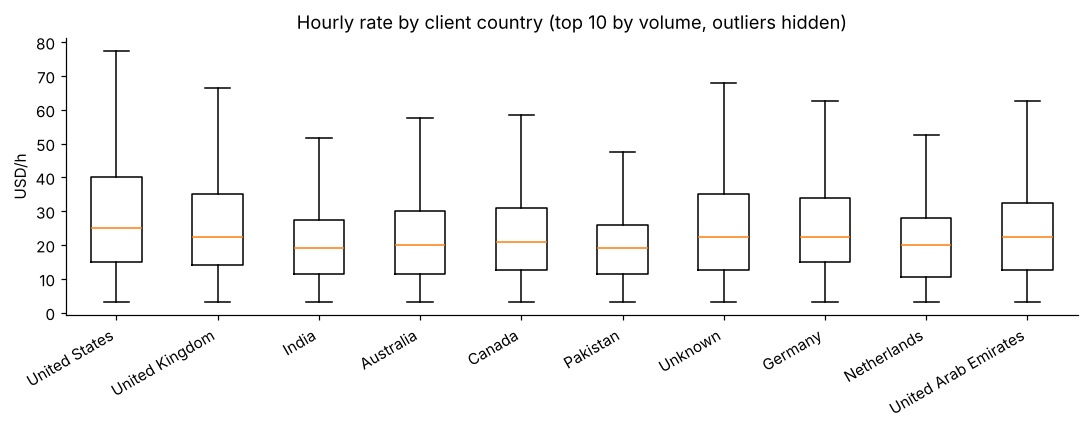

,count,median,mean
country,,,
United States,48096,25.00,31.24
Germany,2075,22.50,27.26
Unknown,2013,22.50,29.09
United Kingdom,8363,22.50,27.94
United Arab Emirates,1296,22.50,25.46
Canada,5229,21.00,25.44
Australia,5884,20.00,23.77
Netherlands,1616,20.00,22.70
Pakistan,1445,19.00,23.58


In [13]:
top_c = df.country.value_counts().head(10).index
box = [df[(df.country == c) & df.is_hourly].hourly_mid.dropna().values for c in top_c]
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot(box, showfliers=False); ax.set_xticks(range(1, len(top_c) + 1), top_c); ax.set_title("Hourly rate by client country (top 10 by volume, outliers hidden)")
ax.set_ylabel("USD/h"); plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()
df[df.country.isin(top_c) & df.is_hourly].groupby("country").hourly_mid.agg(["count", "median", "mean"]).sort_values("median", ascending=False)

**Findings.** The US has the highest median advertised rate among the large markets (about **$25/h**), followed by the UK and Germany (~$22.50); India and Pakistan sit near **$19**. The gap is real but modest, and ranges overlap heavily, so country explains far less than job type does. Smaller countries can top a ranking on a handful of postings, which is why Task 4 adds minimum sample sizes and confidence intervals.

## 8. Remote and long-term wording

In [14]:
sig = df[["remote_mention", "onsite_mention", "longterm_mention"]].mean() * 100
print(sig.round(2).rename({"remote_mention": "remote / work-from-home", "onsite_mention": "on-site / hybrid", "longterm_mention": "long-term / full-time / part-time"}).to_string() + "  (% of titles)")
# Pitfall check: why 'virtual' is NOT counted as a remote signal
virtual = df.title.str.contains(r"\bvirtual\b", case=False)
va = df.title.str.contains(r"\bvirtual assistant", case=False)
print(f"\n'virtual' appears in {virtual.mean():.2%} of titles; {va.sum() / virtual.sum():.0%} of those are 'virtual assistant' (a job title, not a work arrangement)")

remote / work-from-home             0.56
on-site / hybrid                    0.11
long-term / full-time / part-time   1.88  (% of titles)



'virtual' appears in 1.79% of titles; 76% of those are 'virtual assistant' (a job title, not a work arrangement)


**Findings.**
- Only about **0.6%** of titles say "remote" or "work from home" and about **0.1%** say on-site or hybrid. Upwork is remote by default, so the wording is *emphasis*, not a location constraint. Task 7 therefore measures **explicit remote wording**, not the total supply of remote work, which this file cannot measure.
- **Pitfall caught here:** an earlier version of the remote rule also matched the word "virtual". That roughly quadrupled the apparent remote share (2.3% vs 0.6%), because most "virtual" titles are *virtual assistants*, and it made remote jobs look like they paid far less per hour. The rule now excludes it. Always check what a keyword flag actually matches before drawing conclusions from it.
- "Long-term / full-time / part-time" wording appears in about **1.9%** of titles.

## 9. Summary: what EDA means for the modelling tasks

| Finding | Consequence |
|---|---|
| Dense data only 13 Feb - 24 Mar; 15 Feb gap; 24 Mar partial | Train on 16 Feb - 22 Mar; stray rows dropped; forecasts limited to 2-4 weeks |
| Feed likely capped near 7k/day | Prefer shares and growth rates to absolute counts |
| Strong weekday cycle (weekends about a third lower) | Day-of-week terms everywhere; balanced comparison windows |
| Right-skewed pay, placeholder outliers | Log-transform, medians, caps at $3-$300 and $5-$100k |
| ~27% of hourly postings state no rate | Hourly analyses cover only postings with a stated rate |
| HTML entities in titles | `html.unescape` on load |
| A keyword flag can match the wrong thing ("virtual" = virtual assistant) | Remote rule uses only remote / work-from-home wording |
| No category, description or location fields | Categories and remote signals derived from title keywords; documented as a limitation |
| Country concentrated (US ~41%) | Minimum sample size and bootstrap CIs for country comparisons |

**Next:** `src/task1_keywords_salary.py` onward turn these observations into the eight deliverables. `python -m src.run_all` reproduces everything.